# FinGraph AI — 02 | Temporal evaluation & MLP baseline

**Status:** nova eksperimentalna faza, ne mijenja postojeće XGBoost/GraphSAGE rezultate.

U ovoj fazi:
1. Učitavamo **sačuvane testne predikcije** postojećih modela i strogo provjeravamo njihovu usklađenost po `txId`.
2. Računamo **PR-AUC, ROC-AUC, precision, recall, F1, TP/FP/TN/FN** za svaki testni vremenski korak (42–49).
3. Implementiramo **MLP**: neuronsku mrežu koja koristi identične 182 karakteristike, ali **bez eksplicitnih grafovskih veza**.
4. Poredimo tri osnovna modela, spremamo grafikone i tabele.

**Pravilo eksperimenta:** odabir epohe i praga koristi validaciju. Testni podaci služe samo za izvještavanje i **ne smiju biti osnova za daljnje podešavanje hiperparametara**. Rezultati testa iz ranije faze već su pregledani, što treba transparentno navesti u završnom izvještaju.

## 0. Poveži Google Drive i provjeri projekt

Notebook radi s istom Google Drive lokacijom kao faze 00 i 01. Originalni podaci ostaju u `data/raw`, a stari rezultati ostaju u `outputs/xgboost` i `outputs/graphsage`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, sys
PROJECT_DIR = Path('/content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter')
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(f'Projekt ne postoji: {PROJECT_DIR}')
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR / 'src'))

must_exist = [
    'src/fingraph/mlp.py', 'src/fingraph/temporal.py',
    'data/raw/txs_features.csv', 'data/raw/txs_classes.csv', 'data/raw/txs_edgelist.csv',
    'outputs/xgboost/metrics.json', 'outputs/xgboost/test_predictions.csv',
    'outputs/graphsage/metrics.json', 'outputs/graphsage/test_predictions.csv',
]
missing = [p for p in must_exist if not (PROJECT_DIR / p).is_file()]
print('Radni folder:', Path.cwd())
for p in must_exist:
    print('OK       ' if p not in missing else 'NEDOSTAJE', p)
if missing:
    raise FileNotFoundError('Dopuni nedostajuće datoteke prije nastavka: ' + ', '.join(missing))

Mounted at /content/drive
Radni folder: /content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter
OK        src/fingraph/mlp.py
OK        src/fingraph/temporal.py
OK        data/raw/txs_features.csv
OK        data/raw/txs_classes.csv
OK        data/raw/txs_edgelist.csv
OK        outputs/xgboost/metrics.json
OK        outputs/xgboost/test_predictions.csv
OK        outputs/graphsage/metrics.json
OK        outputs/graphsage/test_predictions.csv


## 1. Učitaj postojeće predikcije i provjeri iste testne transakcije

Ne treniramo ponovno stare modele. `metrics.json` daje njihove ranije rezultate i **pragove izabrane na validaciji**, a `test_predictions.csv` omogućava pregled rezultata za svaki vremenski korak. Svaka transakcija mora imati tačan ID, vrijeme i oznaku.

In [2]:
%pip install -q -e .

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from fingraph.data import load_elliptic
from fingraph.splits import make_time_splits
from fingraph.temporal import (
    load_and_check_test_predictions, evaluate_per_time, joined_predictions
)

OUTPUT_DIR = Path('outputs/phase02')
TABLES = OUTPUT_DIR / 'tables'
FIGURES = OUTPUT_DIR / 'figures'
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

graph = load_elliptic('data/raw')
splits = make_time_splits(graph)
print('Čvorova:', graph.num_nodes, '| testnih poznatih oznaka:', int(splits.test.sum()))
model_locations = {
    'XGBoost': Path('outputs/xgboost'),
    'GraphSAGE': Path('outputs/graphsage'),
}
predictions = {}
metrics = {}
for name, folder in model_locations.items():
    metrics[name] = json.loads((folder / 'metrics.json').read_text(encoding='utf-8'))
    predictions[name] = load_and_check_test_predictions(
        folder / 'test_predictions.csv', graph, splits
    )
    recomputed = average_precision_score(
        predictions[name]['label'], predictions[name]['probability_illicit']
    )
    expected = metrics[name]['test']['pr_auc']
    assert np.isclose(recomputed, expected, rtol=1e-5, atol=1e-5), (
        f'{name}: PR-AUC ne odgovara sačuvanim metrikama'
    )
    print(f'{name}: {len(predictions[name]):,} usklađenih testnih redova, PR-AUC={recomputed:.4f}')

aligned = joined_predictions(predictions)
print('Potvrđeno: oba modela imaju iste testne transakcije i oznake.')

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for fingraph-ai-mpvi (pyproject.toml) ... done
Čvorova: 203769 | testnih poznatih oznaka: 8841
XGBoost: 8,841 usklađenih testnih redova, PR-AUC=0.5675
GraphSAGE: 8,841 usklađenih testnih redova, PR-AUC=0.3891
Potvrđeno: oba modela imaju iste testne transakcije i oznake.


## 2. Temporalna evaluacija na koracima 42–49

**Ne biramo novi prag** za svaki korak. Svaki model ima svoj jedinstveni prag iz validacije (XGBoost 0,77; GraphSAGE 0,88 u početnom pokretanju).

Za mali broj pozitivnih primjera pojedinačni PR-AUC može snažno varirati. Koristi ga zajedno s brojem transakcija, osnovnim udjelom pozitivne klase i matricom zabune.

In [3]:
per_time_tables = {}
for name in ['XGBoost', 'GraphSAGE']:
    threshold = metrics[name]['test']['threshold']
    table = evaluate_per_time(predictions[name], threshold)
    table.insert(0, 'model', name)
    per_time_tables[name] = table
    print(f'\n{name} | validacijski prag {threshold:.2f}')
    display(table.round(4))

temporal_all = pd.concat(per_time_tables.values(), ignore_index=True)
temporal_all.to_csv(TABLES / 'temporal_metrics_initial_models.csv', index=False)
print('Sačuvano:', TABLES / 'temporal_metrics_initial_models.csv')


XGBoost | validacijski prag 0.77


,model,time_step,n,positives,positive_rate,predicted_positive,tp,fp,tn,fn,precision,recall,f1,pr_auc,roc_auc
0,XGBoost,42,2154,239,0.1110,200,192,8,1907,47,0.9600,0.8033,0.8747,0.8976,0.9685
1,XGBoost,43,1370,24,0.0175,2,0,2,1344,24,0.0000,0.0000,0.0000,0.0552,0.7847
2,XGBoost,44,1591,24,0.0151,14,1,13,1554,23,0.0714,0.0417,0.0526,0.0515,0.7268
3,XGBoost,45,1221,5,0.0041,3,0,3,1213,5,0.0000,0.0000,0.0000,0.0145,0.7405
4,XGBoost,46,712,2,0.0028,6,1,5,705,1,0.1667,0.5000,0.2500,0.5111,0.9380
5,XGBoost,47,846,22,0.0260,2,0,2,822,22,0.0000,0.0000,0.0000,0.0536,0.7675
6,XGBoost,48,471,36,0.0764,0,0,0,435,36,0.0000,0.0000,0.0000,0.2451,0.8542
7,XGBoost,49,476,56,0.1176,4,1,3,417,55,0.2500,0.0179,0.0333,0.2596,0.8168



GraphSAGE | validacijski prag 0.88


,model,time_step,n,positives,positive_rate,predicted_positive,tp,fp,tn,fn,precision,recall,f1,pr_auc,roc_auc
0,GraphSAGE,42,2154,239,0.1110,184,145,39,1876,94,0.7880,0.6067,0.6856,0.7680,0.9392
1,GraphSAGE,43,1370,24,0.0175,12,0,12,1334,24,0.0000,0.0000,0.0000,0.0375,0.7506
2,GraphSAGE,44,1591,24,0.0151,75,1,74,1493,23,0.0133,0.0417,0.0202,0.0571,0.5483
3,GraphSAGE,45,1221,5,0.0041,29,0,29,1187,5,0.0000,0.0000,0.0000,0.0105,0.7104
4,GraphSAGE,46,712,2,0.0028,8,0,8,702,2,0.0000,0.0000,0.0000,0.0125,0.6254
5,GraphSAGE,47,846,22,0.0260,4,0,4,820,22,0.0000,0.0000,0.0000,0.0646,0.7962
6,GraphSAGE,48,471,36,0.0764,1,0,1,434,36,0.0000,0.0000,0.0000,0.3738,0.9227
7,GraphSAGE,49,476,56,0.1176,18,1,17,403,55,0.0556,0.0179,0.0270,0.0740,0.1669


Sačuvano: outputs/phase02/tables/temporal_metrics_initial_models.csv


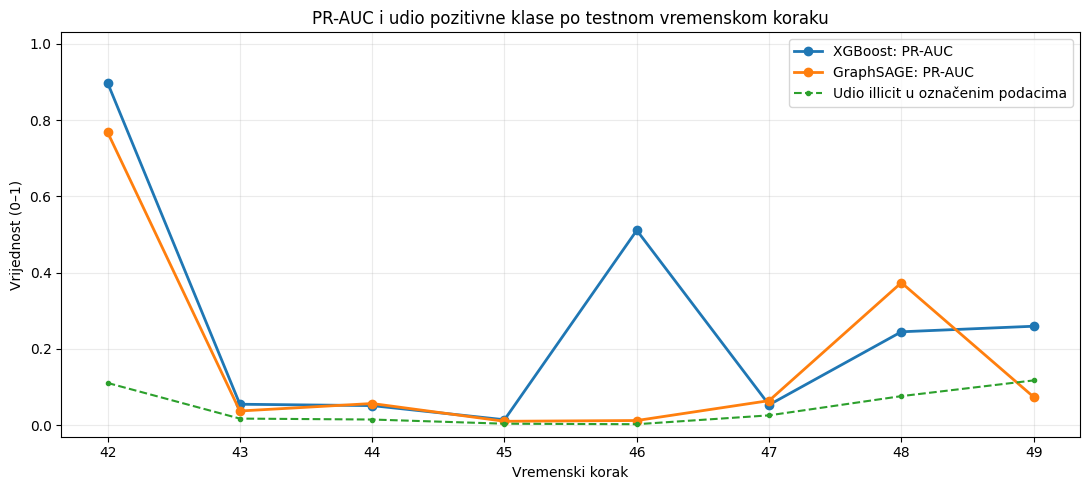

In [4]:
# PR-AUC prema vremenu uz referentni udio pozitivne klase
fig, ax = plt.subplots(figsize=(11, 5))
for name, table in per_time_tables.items():
    ax.plot(table['time_step'], table['pr_auc'], marker='o', linewidth=2, label=f'{name}: PR-AUC')
ax.plot(per_time_tables['XGBoost']['time_step'],
        per_time_tables['XGBoost']['positive_rate'],
        linestyle='--', marker='.', label='Udio illicit u označenim podacima')
ax.set_title('PR-AUC i udio pozitivne klase po testnom vremenskom koraku')
ax.set_xlabel('Vremenski korak')
ax.set_ylabel('Vrijednost (0–1)')
ax.set_ylim(-0.03, 1.03)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES / '01_pr_auc_by_time.png', dpi=180, bbox_inches='tight')
plt.show()

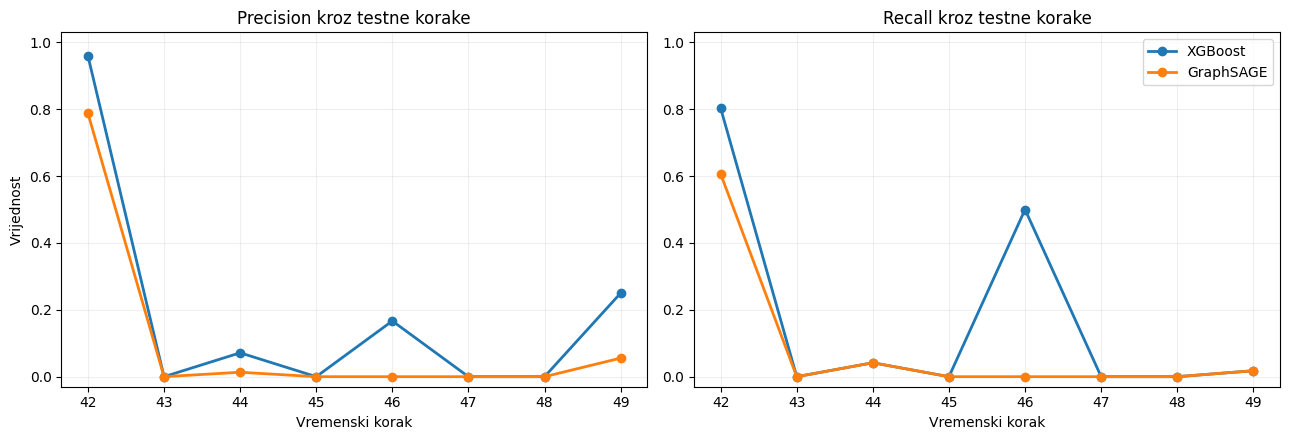

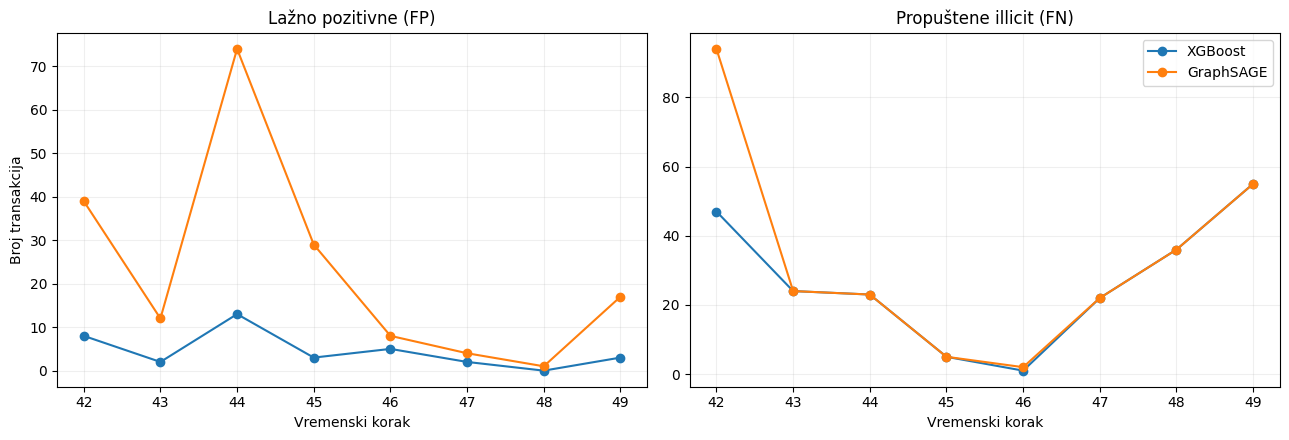

In [5]:
# Precision/recall kroz vrijeme; interpretirati zajedno s brojem pozitivnih primjera
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, table in per_time_tables.items():
    for ax, metric in zip(axes, ['precision', 'recall']):
        ax.plot(table['time_step'], table[metric], marker='o', linewidth=2, label=name)
        ax.set_title(f'{metric.capitalize()} kroz testne korake')
        ax.set_xlabel('Vremenski korak')
        ax.set_ylim(-0.03, 1.03)
        ax.grid(alpha=0.2)
axes[0].set_ylabel('Vrijednost')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / '02_precision_recall_by_time.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, table in per_time_tables.items():
    axes[0].plot(table['time_step'], table['fp'], marker='o', label=name)
    axes[1].plot(table['time_step'], table['fn'], marker='o', label=name)
for ax, title in zip(axes, ['Lažno pozitivne (FP)', 'Propuštene illicit (FN)']):
    ax.set_title(title)
    ax.set_xlabel('Vremenski korak')
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Broj transakcija')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / '03_error_counts_by_time.png', dpi=180, bbox_inches='tight')
plt.show()

### Tumačenje temporalne evaluacije

Obrati pažnju na korake **42–49**. U nekim koracima ima vrlo malo označenih nezakonitih transakcija (npr. korak 46 ima samo 2). Zato jednu vrijednost metrike ne treba automatski smatrati dokazom da je model postao bolji ili lošiji.

Ova analiza pokazuje **kada** modeli griješe, ne dokazuje sama po sebi **zašto**. Ukupni testni PR-AUC nije isto što i obični prosjek PR-AUC vrijednosti po vremenskim koracima.

## 3. MLP — kontrolni neuronski model bez grafovskih veza

Zašto MLP? Dosadašnji XGBoost ne koristi `edge_index`, ali među njegovim karakteristikama već postoje agregirane mrežne vrijednosti. GraphSAGE koristi iste ulaze uz eksplicitne veze. MLP omogućava da uporedimo **duboko učenje bez propagacije po grafu** i **duboko učenje s propagacijom po grafu**.

Za fer kontrolu koristimo:
- iste 182 ulazne karakteristike kao GraphSAGE;
- iste granice: trening 1–34, validacija 35–41, test 42–49;
- imputaciju medijanom i StandardScaler naučene na prethodno opaženom trening periodu;
- ponderisani cross-entropy, dropout i Adam;
- izbor epohe prema validacijskom PR-AUC;
- prag klasifikacije izabran samo na validaciji.

**NAPOMENA:** MLP bez `edge_index` nije potpuno nezavisan od mrežnih informacija jer među 182 ulazne karakteristike postoje i izvorno agregirane karakteristike. Eksperiment samo s lokalnim karakteristikama planiran je za fazu 03.

Ova ćelija trenira MLP, ali ne dira postojeće `outputs/xgboost` ili `outputs/graphsage`.

In [6]:
import torch
from fingraph.mlp import run as train_mlp

print('PyTorch:', torch.__version__, '| CUDA dostupna:', torch.cuda.is_available())
mlp_result = train_mlp(
    data_dir='data/raw',
    output_dir='outputs/mlp_v1',
    seed=42,
    epochs=150,
    hidden_dim=128,
    lr=0.001,
    dropout=0.3,
    patience=20,
)
print('\nMLP – najbolja epoha:', mlp_result['best_epoch'])
print('MLP – validacija PR-AUC:', round(mlp_result['validation']['pr_auc'], 4))
print('MLP – test PR-AUC:', round(mlp_result['test']['pr_auc'], 4))
print('MLP rezultati su u outputs/mlp_v1/')

PyTorch: 2.11.0+cu130 | CUDA dostupna: True
Epoch 001 | train loss=0.6629 | val PR-AUC=0.4986
Epoch 002 | train loss=0.6351 | val PR-AUC=0.6251
Epoch 003 | train loss=0.6099 | val PR-AUC=0.6639
Epoch 004 | train loss=0.5867 | val PR-AUC=0.6800
Epoch 005 | train loss=0.5648 | val PR-AUC=0.6892
Epoch 006 | train loss=0.5454 | val PR-AUC=0.6981
Epoch 007 | train loss=0.5281 | val PR-AUC=0.7051
Epoch 008 | train loss=0.5110 | val PR-AUC=0.7114
Epoch 009 | train loss=0.4958 | val PR-AUC=0.7124
Epoch 010 | train loss=0.4798 | val PR-AUC=0.7092
Epoch 011 | train loss=0.4664 | val PR-AUC=0.7087
Epoch 012 | train loss=0.4517 | val PR-AUC=0.7065
Epoch 013 | train loss=0.4413 | val PR-AUC=0.7046
Epoch 014 | train loss=0.4284 | val PR-AUC=0.7019
Epoch 015 | train loss=0.4122 | val PR-AUC=0.6990
Epoch 016 | train loss=0.4019 | val PR-AUC=0.6963
Epoch 017 | train loss=0.3907 | val PR-AUC=0.6968
Epoch 018 | train loss=0.3798 | val PR-AUC=0.6998
Epoch 019 | train loss=0.3654 | val PR-AUC=0.7033
Epoch 

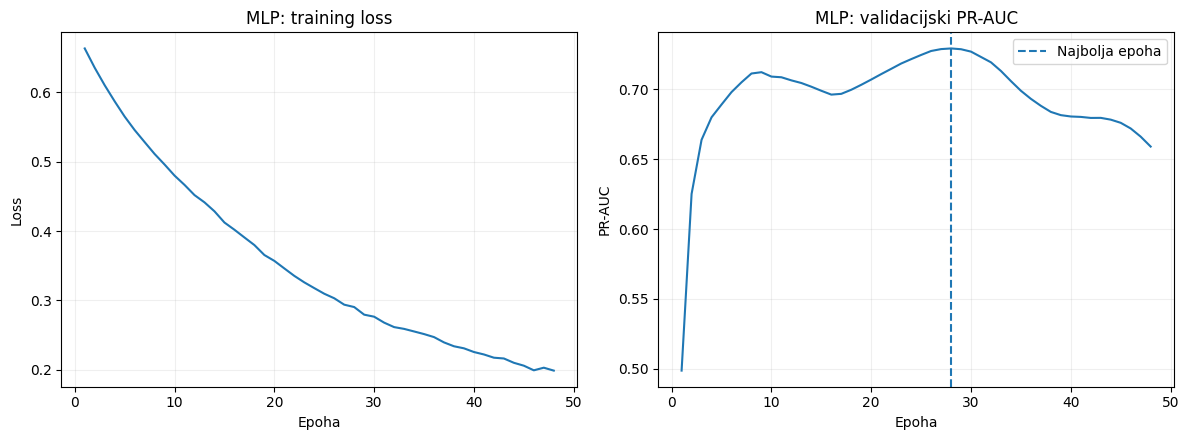

In [7]:
history = pd.read_csv('outputs/mlp_v1/training_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history['epoch'], history['train_loss'])
axes[0].set_title('MLP: training loss')
axes[0].set_xlabel('Epoha')
axes[0].set_ylabel('Loss')
axes[0].grid(alpha=0.2)
axes[1].plot(history['epoch'], history['val_pr_auc'])
axes[1].axvline(mlp_result['best_epoch'], linestyle='--', label='Najbolja epoha')
axes[1].set_title('MLP: validacijski PR-AUC')
axes[1].set_xlabel('Epoha')
axes[1].set_ylabel('PR-AUC')
axes[1].legend()
axes[1].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / '04_mlp_training_history.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Usporedi tri modela na istom testnom skupu

Koristimo već spremljene predikcije XGBoost/GraphSAGE i nove MLP predikcije. Najprije poravnamo `txId`, vremenski korak i stvarnu oznaku; zatim prikazujemo metrike i krivulje.

**Važno:** rezultat MLP-a na testu gledamo samo radi izvještaja, a ne da bismo pomoću njega birali nove hiperparametre. Za sve sljedeće eksperimente primarna osnova za izbor bit će validacija.

,valid_pr_auc,test_pr_auc,test_roc_auc,test_precision,test_recall,test_f1,precision_at_100,threshold_from_validation
model,,,,,,,,
XGBoost,0.9341,0.5675,0.8718,0.8442,0.4779,0.6103,1.00,0.77
GraphSAGE,0.5402,0.3891,0.7876,0.4441,0.3603,0.3978,0.85,0.88
MLP,0.7294,0.3707,0.8253,0.3271,0.4706,0.3859,0.73,0.91


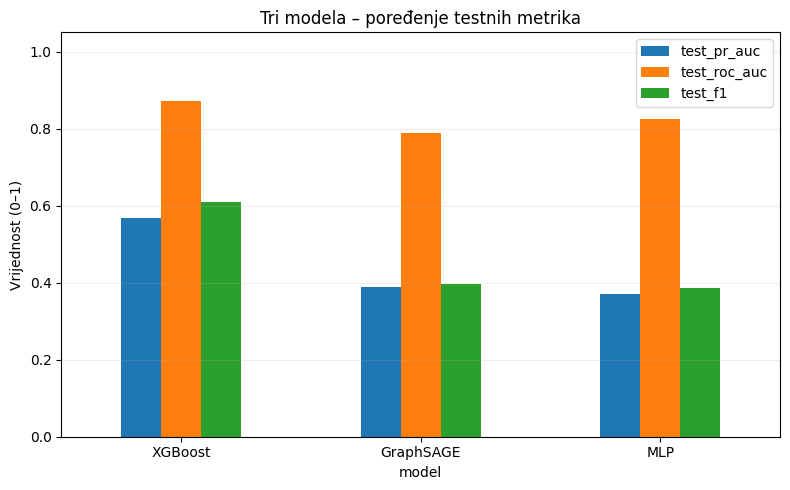

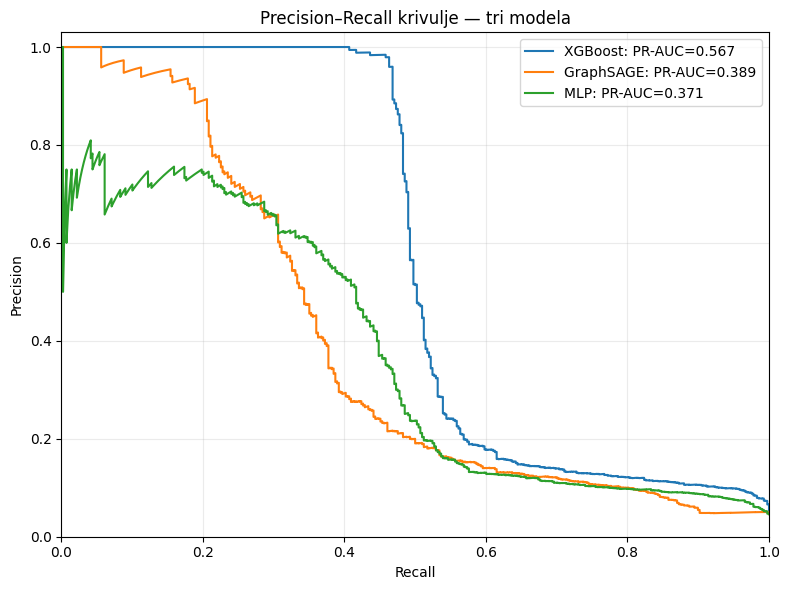

In [8]:
mlp_dir = Path('outputs/mlp_v1')
metrics['MLP'] = json.loads((mlp_dir / 'metrics.json').read_text(encoding='utf-8'))
predictions['MLP'] = load_and_check_test_predictions(
    mlp_dir / 'test_predictions.csv', graph, splits
)
aligned = joined_predictions(predictions)
assert len(aligned) == int(splits.test.sum())

comparison = pd.DataFrame([
    {
        'model': name,
        'valid_pr_auc': value['validation']['pr_auc'],
        'test_pr_auc': value['test']['pr_auc'],
        'test_roc_auc': value['test']['roc_auc'],
        'test_precision': value['test']['precision'],
        'test_recall': value['test']['recall'],
        'test_f1': value['test']['f1'],
        'precision_at_100': value['test']['precision_at_100_or_less'],
        'threshold_from_validation': value['test']['threshold'],
    }
    for name, value in metrics.items()
]).set_index('model')
display(comparison.round(4))
comparison.to_csv(TABLES / 'baseline_comparison_three_models.csv')
aligned.to_csv(TABLES / 'aligned_test_predictions_three_models.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 5))
comparison[['test_pr_auc', 'test_roc_auc', 'test_f1']].plot(kind='bar', ax=ax, rot=0)
ax.set_title('Tri modela – poređenje testnih metrika')
ax.set_ylabel('Vrijednost (0–1)')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / '05_three_model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, frame in predictions.items():
    precision, recall, _ = precision_recall_curve(
        frame['label'], frame['probability_illicit']
    )
    ap = average_precision_score(frame['label'], frame['probability_illicit'])
    ax.plot(recall, precision, label=f'{name}: PR-AUC={ap:.3f}')
ax.set_title('Precision–Recall krivulje — tri modela')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.03)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / '06_three_model_pr_curves.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Temporalne metrike i za MLP

Poredi se isti testni period. Ako je u nekim koracima vrlo mali broj pozitivnih primjera, uvijek pregledaj i `n`, `positives`, `tp`, `fp`, `fn`, a ne samo PR-AUC.

,model,time_step,n,positives,positive_rate,predicted_positive,tp,fp,tn,fn,precision,recall,f1,pr_auc,roc_auc
0,XGBoost,42,2154,239,0.1110,200,192,8,1907,47,0.9600,0.8033,0.8747,0.8976,0.9685
1,XGBoost,43,1370,24,0.0175,2,0,2,1344,24,0.0000,0.0000,0.0000,0.0552,0.7847
2,XGBoost,44,1591,24,0.0151,14,1,13,1554,23,0.0714,0.0417,0.0526,0.0515,0.7268
3,XGBoost,45,1221,5,0.0041,3,0,3,1213,5,0.0000,0.0000,0.0000,0.0145,0.7405
4,XGBoost,46,712,2,0.0028,6,1,5,705,1,0.1667,0.5000,0.2500,0.5111,0.9380
5,XGBoost,47,846,22,0.0260,2,0,2,822,22,0.0000,0.0000,0.0000,0.0536,0.7675
6,XGBoost,48,471,36,0.0764,0,0,0,435,36,0.0000,0.0000,0.0000,0.2451,0.8542
7,XGBoost,49,476,56,0.1176,4,1,3,417,55,0.2500,0.0179,0.0333,0.2596,0.8168
8,GraphSAGE,42,2154,239,0.1110,184,145,39,1876,94,0.7880,0.6067,0.6856,0.7680,0.9392
9,GraphSAGE,43,1370,24,0.0175,12,0,12,1334,24,0.0000,0.0000,0.0000,0.0375,0.7506


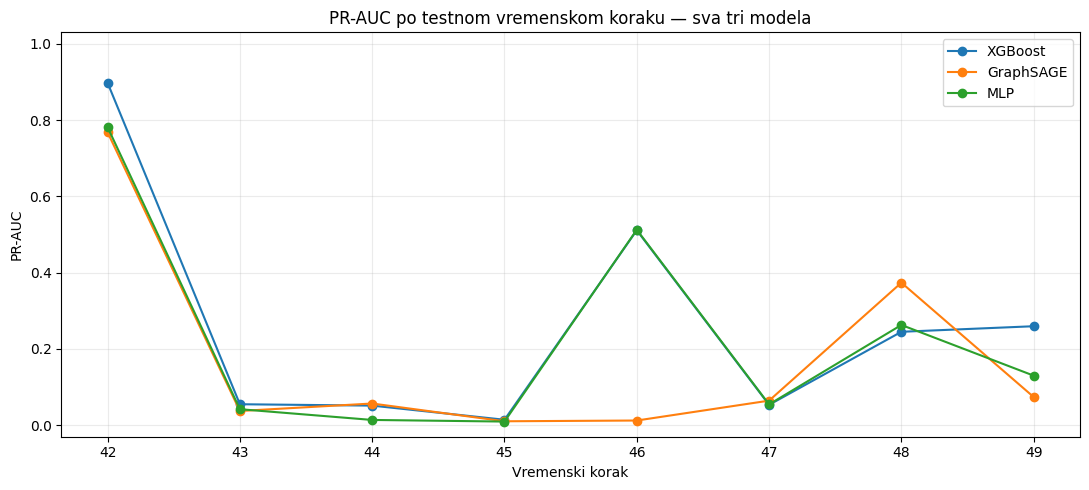

In [9]:
mlp_temporal = evaluate_per_time(
    predictions['MLP'], metrics['MLP']['test']['threshold']
)
mlp_temporal.insert(0, 'model', 'MLP')
full_temporal = pd.concat([temporal_all, mlp_temporal], ignore_index=True)
full_temporal.to_csv(TABLES / 'temporal_metrics_all_models.csv', index=False)
display(full_temporal.round(4))

fig, ax = plt.subplots(figsize=(11, 5))
for name, frame in full_temporal.groupby('model', sort=False):
    ax.plot(frame['time_step'], frame['pr_auc'], marker='o', label=name)
ax.set_title('PR-AUC po testnom vremenskom koraku — sva tri modela')
ax.set_xlabel('Vremenski korak')
ax.set_ylabel('PR-AUC')
ax.set_ylim(-0.03, 1.03)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES / '07_all_models_pr_auc_by_time.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Automatski izvještaj o rezultatima i plan naredne faze

Ovdje samo ispisujemo vrijednosti iz tvog pokretanja. Ne pretpostavljamo unaprijed da je MLP bolji od nekog modela.

**Naredna faza 03:** ablacijski eksperimenti s lokalnim karakteristikama, optimizacija GraphSAGE modela i analiza potencijalno visokorizičnih podgrafova. Ne uvoditi nove promjene na osnovu rezultata testa iz faze 02; promjene ćemo unaprijed definisati i birati prema validacijskim rezultatima.

In [10]:
summary = {
    'phase': '02_temporal_evaluation_and_mlp_baseline',
    'dataset': 'Elliptic++ Transactions',
    'split': {'train_end': splits.train_end, 'valid_end': splits.valid_end},
    'test_n': int(splits.test.sum()),
    'models': metrics,
    'note': 'Eksplorativna vremenska analiza, bez izbora hiperparametara na testu.',
}
(OUTPUT_DIR / 'phase02_summary.json').write_text(
    json.dumps(summary, indent=2), encoding='utf-8'
)

print('Faza 02 završena. Provjeri:')
print('-', OUTPUT_DIR / 'phase02_summary.json')
print('-', TABLES / 'temporal_metrics_all_models.csv')
print('-', TABLES / 'baseline_comparison_three_models.csv')
print('-', Path('outputs/mlp_v1/metrics.json'))
print('-', Path('outputs/mlp_v1/training_history.csv'))
print('- grafikoni:', FIGURES)
print('\nTop 3 vremenska koraka s najviše XGBoost propuštenih slučajeva:')
display(per_time_tables['XGBoost'].sort_values('fn', ascending=False)[
    ['time_step','positives','tp','fn','fp','recall','pr_auc']
].head(3).round(4))
print('\nNaredni korak: dostaviti izvršeni .ipynb s outputima za detaljnu interpretaciju.')

Faza 02 završena. Provjeri:
- outputs/phase02/phase02_summary.json
- outputs/phase02/tables/temporal_metrics_all_models.csv
- outputs/phase02/tables/baseline_comparison_three_models.csv
- outputs/mlp_v1/metrics.json
- outputs/mlp_v1/training_history.csv
- grafikoni: outputs/phase02/figures

Top 3 vremenska koraka s najviše XGBoost propuštenih slučajeva:


,time_step,positives,tp,fn,fp,recall,pr_auc
7,49,56,1,55,3,0.0179,0.2596
0,42,239,192,47,8,0.8033,0.8976
6,48,36,0,36,0,0.0000,0.2451



Naredni korak: dostaviti izvršeni .ipynb s outputima za detaljnu interpretaciju.


## 7. Šta se predaje i šta slijedi?

Za sljedeći izvještaj sačuvaj ovaj notebook s outputima i posebno datoteke:
- `outputs/phase02/tables/temporal_metrics_all_models.csv`
- `outputs/phase02/tables/baseline_comparison_three_models.csv`
- `outputs/mlp_v1/metrics.json`
- `outputs/mlp_v1/training_history.csv`

**Ne dodavati sirovi Elliptic++ dataset ni kompletan `outputs/` folder na GitHub.** Kod i notebook smiju se verzionisati, dok rezultate po potrebi možemo dodati u kontrolisanom, malom izvještajnom obliku.

### Metodološka ograničenja
1. Svi modeli koriste objavljene agregirane karakteristike; dio tih karakteristika već može sadržavati mrežne informacije.
2. GraphSAGE sada konvertuje usmjerene veze u dvosmjerne pri message-passingu.
3. Sve originalne transakcijske veze nalaze se unutar istog vremenskog koraka; evaluacija po vremenu **ne čini** model temporalnim GNN-om.
4. `Unknown` čvorovi nisu negativni primjeri; metrike važe isključivo za poznato označene transakcije.
5. Test je već korišten za pregled početnih rezultata. Za formalnu selekciju konfiguracija koristiti isključivo validaciju i jasno dokumentovati razvojni proces.